In [1]:
import os
import random
import torch
import torchvision
import numpy as np
import torch.nn as nn
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torchvision import transforms, datasets, models
from torchvision.models import ResNet18_Weights

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# Menentukan apakah komputasi menggunakan GPU (CUDA) atau CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device yang aktif: {device}")

Device yang aktif: cuda


In [2]:
# Unduh kedua split tanpa transformasi awal (transformasi diterapkan nanti)
raw_trainval = datasets.OxfordIIITPet(root='./data', split='trainval', target_types='category', download=True)
raw_test = datasets.OxfordIIITPet(root='./data', split='test', target_types='category', download=True)

full_raw_dataset = ConcatDataset([raw_trainval, raw_test])
classes = raw_trainval.classes

target_class_names = [
    # 5 Kucing
    'Abyssinian', 'Bengal', 'Birman', 'Persian', 'Ragdoll',
    # 5 Anjing
    'Chihuahua', 'Boxer', 'English Cocker Spaniel', 'Pomeranian', 'Pug'
]

# Pemetaan: Class Name -> ID Asli (0..36)
selected_orig_indices = {cls_name: classes.index(cls_name) for cls_name in target_class_names}
# Pemetaan baru: ID Asli -> ID Baru (0..9)
orig_to_new_label = {orig_idx: new_idx for new_idx, orig_idx in enumerate(selected_orig_indices.values())}
new_label_to_name = {new_idx: cls_name for cls_name, new_idx in zip(target_class_names, range(10))}

print("Pemetaan 10 Kelas Terpilih:")
for new_id, name in new_label_to_name.items():
    print(f"  ID {new_id}: {name}")

filtered_samples = []  # Menyimpan tuple: (PIL_Image, new_label)
for img, orig_label in full_raw_dataset:
    if orig_label in orig_to_new_label:
        new_label = orig_to_new_label[orig_label]
        filtered_samples.append((img, new_label))
print(f"\nTotal citra subset 10 kelas terkumpul: {len(filtered_samples)}")

Pemetaan 10 Kelas Terpilih:
  ID 0: Abyssinian
  ID 1: Bengal
  ID 2: Birman
  ID 3: Persian
  ID 4: Ragdoll
  ID 5: Chihuahua
  ID 6: Boxer
  ID 7: English Cocker Spaniel
  ID 8: Pomeranian
  ID 9: Pug

Total citra subset 10 kelas terkumpul: 1993


In [3]:
# Pisahkan citra dan label ke dalam list terpisah
images = [item[0] for item in filtered_samples]
labels = [item[1] for item in filtered_samples]

# Tahap 1: 70% Train, 30% Temp (Val + Test)
train_imgs, temp_imgs, train_lbls, temp_lbls = train_test_split(
    images, labels,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

# Tahap 2: 15% Val, 15% Test (dari 30% Temp, dibagi 50:50)
val_imgs, test_imgs, val_lbls, test_lbls = train_test_split(
    temp_imgs, temp_lbls,
    test_size=0.50,
    stratify=temp_lbls,
    random_state=42
)

print(f"Jumlah Train set      : {len(train_imgs)} ({len(train_imgs)/len(labels)*100:.1f}%)")
print(f"Jumlah Validation set : {len(val_imgs)} ({len(val_imgs)/len(labels)*100:.1f}%)")
print(f"Jumlah Test set       : {len(test_imgs)} ({len(test_imgs)/len(labels)*100:.1f}%)")

# Verifikasi distribusi kelas pada Test set
print("Distribusi per kelas di Test set:", sorted(Counter(test_lbls).items()))

Jumlah Train set      : 1395 (70.0%)
Jumlah Validation set : 299 (15.0%)
Jumlah Test set       : 299 (15.0%)
Distribusi per kelas di Test set: [(0, 30), (1, 30), (2, 30), (3, 30), (4, 30), (5, 30), (6, 30), (7, 29), (8, 30), (9, 30)]


In [4]:
imagenet_weights = ResNet18_Weights.IMAGENET1K_V1
norm_mean = imagenet_weights.transforms().mean
norm_std = imagenet_weights.transforms().std

# Data Latih: Augmentasi aktif
train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=norm_mean, std=norm_std),
])

# Data Validasi & Uji: Deterministik tanpa distorsi acak
eval_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=norm_mean, std=norm_std),
])


class PetSubsetDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]
        label = self.labels[idx]

        # Konversi ke RGB jika format gambar RGBA / Grayscale
        if img.mode != 'RGB':
            img = img.convert('RGB')

        if self.transform:
            img = self.transform(img)

        return img, torch.tensor(label, dtype=torch.long)

# Buat instance dataset
train_dataset = PetSubsetDataset(train_imgs, train_lbls, transform=train_transforms)
val_dataset   = PetSubsetDataset(val_imgs, val_lbls, transform=eval_transforms)
test_dataset  = PetSubsetDataset(test_imgs, test_lbls, transform=eval_transforms)

Total Batch Train : 44
Total Batch Val   : 10
Total Batch Test  : 10


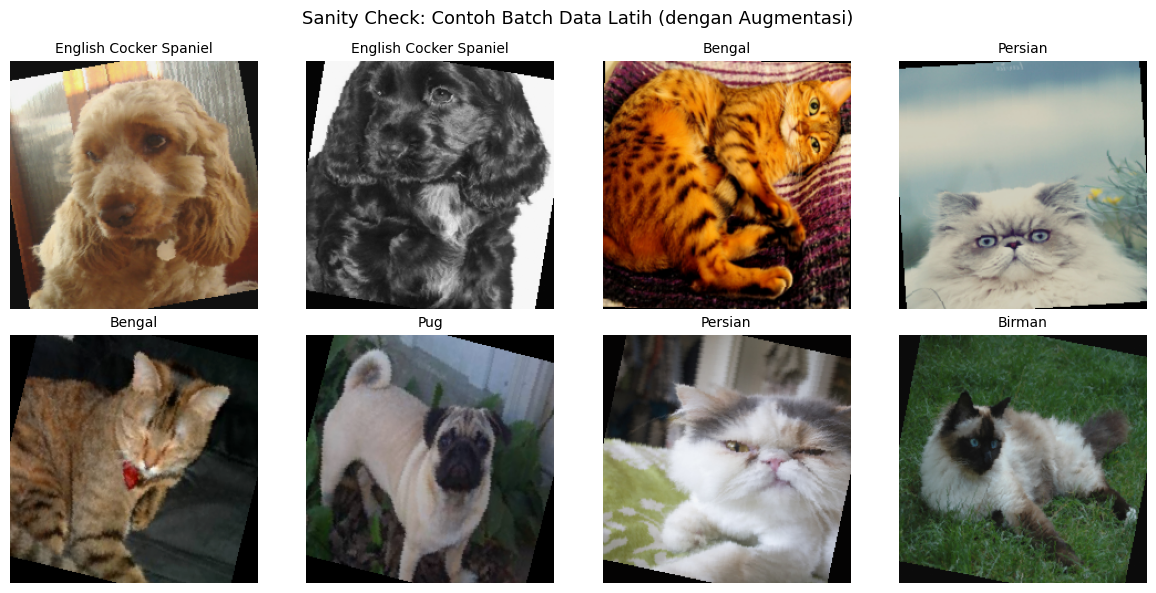

In [5]:
BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Total Batch Train : {len(train_loader)}")
print(f"Total Batch Val   : {len(val_loader)}")
print(f"Total Batch Test  : {len(test_loader)}")


def unnormalize(tensor, mean=norm_mean, std=norm_std):
    """Mengembalikan tensor ternormalisasi ke citra asli untuk visualisasi."""
    tensor = tensor.clone().detach().cpu()
    for t, m, s in zip(tensor, mean, std):
        t.mul_(s).add_(m)
    return torch.clamp(tensor, 0, 1)

# Ambil satu batch data latih
sample_imgs, sample_labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    img = unnormalize(sample_imgs[i]).permute(1, 2, 0).numpy()
    label_idx = sample_labels[i].item()
    ax.imshow(img)
    ax.set_title(new_label_to_name[label_idx], fontsize=10)
    ax.axis("off")

plt.suptitle("Sanity Check: Contoh Batch Data Latih (dengan Augmentasi)", fontsize=13)
plt.tight_layout()
plt.show()

In [6]:
def build_model(condition: str, num_classes: int = 10):
    """
    Membangun model sesuai kondisi eksperimen (B1, B2, B3, B4, B5).

    Args:
        condition: 'B1', 'B2', 'B3', 'B4_no_aug', 'B4_aug', atau 'B5'
        num_classes: Jumlah kelas klasifikasi (default: 10)

    Returns:
        model: PyTorch nn.Module yang sudah dikonfigurasi gradiennya.
    """

    # -------------------------------------------------------------
    # B1: BASELINE FROM SCRATCH (ResNet-18 Acak)
    # -------------------------------------------------------------
    if condition == 'B1':
        # weights=None: Inisialisasi bobot acak (tidak pretrained)
        model = models.resnet18(weights=None)

        # Ganti linear head untuk 10 kelas
        num_ftrs = model.fc.in_features  # 512
        model.fc = nn.Linear(num_ftrs, num_classes)

        # Seluruh layer aktif dilatih (requires_grad = True secara default)
        for param in model.parameters():
            param.requires_grad = True

        return model

    # -------------------------------------------------------------
    # B2: FEATURE EXTRACTION (ResNet-18 Backbone Frozen)
    # -------------------------------------------------------------
    elif condition == 'B2':
        # Muat bobot resmi ImageNet-1K V1
        weights = models.ResNet18_Weights.IMAGENET1K_V1
        model = models.resnet18(weights=weights)

        # Bekukan seluruh parameter backbone
        for param in model.parameters():
            param.requires_grad = False

        # Ganti linear classifier head (layer baru ini otomatis requires_grad=True)
        num_ftrs = model.fc.in_features
        model.fc = nn.Linear(num_ftrs, num_classes)

        return model

    # -------------------------------------------------------------
    # B3 & B4: PROGRESSIVE FINE-TUNING (Unfreeze layer4 + fc)
    # -------------------------------------------------------------
    elif condition in ['B3', 'B4_no_aug', 'B4_aug']:
        weights = models.ResNet18_Weights.IMAGENET1K_V1
        model = models.resnet18(weights=weights)

        # 1. Bekukan seluruh layer terlebih dahulu
        for param in model.parameters():
            param.requires_grad = False

        # 2. Buka pembekuan khusus blok residual terakhir (layer4)
        for param in model.layer4.parameters():
            param.requires_grad = True

        # 3. Ganti classifier head
        num_ftrs = model.fc.in_features
        model.fc = nn.Linear(num_ftrs, num_classes)

        return model

    # -------------------------------------------------------------
    # B5: ARSITEKTUR PEMBANDING (EfficientNet-B0)
    # -------------------------------------------------------------
    elif condition == 'B5':
        weights = models.EfficientNet_B0_Weights.DEFAULT
        model = models.efficientnet_b0(weights=weights)

        # Bekukan seluruh backbone
        for param in model.parameters():
            param.requires_grad = False

        # Buka pembekuan blok fitur level tinggi terakhir (features[7] dan features[8])
        for param in model.features[7].parameters():
            param.requires_grad = True
        for param in model.features[8].parameters():
            param.requires_grad = True

        # Ganti classifier head: model.classifier[1] adalah Linear layer
        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_features, num_classes)

        return model

    else:
        raise ValueError(f"Kondisi {condition} tidak dikenali.")

In [7]:
def build_optimizer(model, condition: str, base_lr: float = 1e-3, weight_decay: float = 1e-2):
    """
    Membangun optimizer AdamW sesuai spesifikasi parameter groups masing-masing kondisi.
    """
    if condition == 'B1':
        # Seluruh model dilatih dengan lr konstan
        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=base_lr,
            weight_decay=weight_decay
        )

    elif condition == 'B2':
        # Hanya parameter head (model.fc) yang dilewatkan ke optimizer
        optimizer = torch.optim.AdamW(
            model.fc.parameters(),
            lr=base_lr,
            weight_decay=weight_decay
        )

    elif condition in ['B3', 'B4_no_aug', 'B4_aug']:
        # Differential Learning Rate:
        # layer4: lr = 1e-4, fc: lr = 1e-3
        optimizer = torch.optim.AdamW([
            {"params": model.layer4.parameters(), "lr": 1e-4},
            {"params": model.fc.parameters(),     "lr": base_lr}
        ], weight_decay=weight_decay)

    elif condition == 'B5':
        # EfficientNet-B0 fine-tuning:
        # features 7 & 8: lr = 1e-4, classifier: lr = 1e-3
        head_params = list(model.classifier.parameters())
        backbone_unfrozen = list(model.features[7].parameters()) + list(model.features[8].parameters())

        optimizer = torch.optim.AdamW([
            {"params": backbone_unfrozen, "lr": 1e-4},
            {"params": head_params,       "lr": base_lr}
        ], weight_decay=weight_decay)

    return optimizer

In [8]:
def count_parameters(model):
    """Menghitung total parameter dan parameter yang aktif dilatih."""
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total_params = sum(p.numel() for p in model.parameters())
    return trainable_params, total_params

def print_model_summary(model, condition_name):
    trainable, total = count_parameters(model)
    percentage = (trainable / total) * 100
    print(f"[{condition_name:10s}] Trainable: {trainable:>10,d} | Total: {total:>10,d} | Trainable Ratio: {percentage:6.2f}%")

In [9]:
print("=" * 70)
print("VERIFIKASI JUMLAH PARAMETER MODEL (B1 s.d. B5)")
print("=" * 70)

conditions_to_test = ['B1', 'B2', 'B3', 'B5']

for cond in conditions_to_test:
    test_model = build_model(cond, num_classes=10)
    print_model_summary(test_model, cond)

print("=" * 70)

VERIFIKASI JUMLAH PARAMETER MODEL (B1 s.d. B5)
[B1        ] Trainable: 11,181,642 | Total: 11,181,642 | Trainable Ratio: 100.00%
[B2        ] Trainable:      5,130 | Total: 11,181,642 | Trainable Ratio:   0.05%
[B3        ] Trainable:  8,398,858 | Total: 11,181,642 | Trainable Ratio:  75.11%
[B5        ] Trainable:  1,142,202 | Total:  4,020,358 | Trainable Ratio:  28.41%


In [10]:
import copy
import time
import json
import pandas as pd
from sklearn.metrics import f1_score, accuracy_score

class EarlyStopping:
    """
    Memantau validation loss dan menghentikan pelatihan jika tidak membaik
    setelah sejumlah epoch tertentu (patience), sekaligus menyimpan bobot terbaik.
    """
    def __init__(self, patience: int = 4, min_delta: float = 1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = float('inf')
        self.early_stop = False
        self.best_model_weights = None
        self.best_epoch = 0

    def __call__(self, val_loss: float, model: torch.nn.Module, epoch: int):
        # Cek apakah val_loss membaik secara signifikan
        if val_loss < (self.best_loss - self.min_delta):
            self.best_loss = val_loss
            self.best_epoch = epoch
            self.best_model_weights = copy.deepcopy(model.state_dict())
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

In [11]:
def evaluate(model, dataloader, criterion, device):
    """
    Evaluasi model dalam mode eval() tanpa komputasi gradien.
    Mengembalikan: average_loss, accuracy, macro_f1, all_preds, all_targets
    """
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, targets)

            running_loss += loss.item() * inputs.size(0)
            preds = torch.argmax(outputs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

    total_samples = len(dataloader.dataset)
    avg_loss = running_loss / total_samples
    acc = accuracy_score(all_targets, all_preds)
    macro_f1 = f1_score(all_targets, all_preds, average='macro', zero_division=0)

    return avg_loss, acc, macro_f1, all_preds, all_targets

In [12]:
def train_experiment(
    condition_name: str,
    model: torch.nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    test_loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: torch.nn.Module,
    device: torch.device,
    max_epochs: int = 25,
    patience: int = 4
):
    """
    Melatih model untuk satu kondisi eksperimen, menerapkan early stopping,
    memulihkan model terbaik, mengevaluasi di test set, dan mencatat metrik.
    """
    print(f"\n{'='*70}")
    print(f"MEMULAI EKSPERIMEN: {condition_name}")
    print(f"{'='*70}")

    model = model.to(device)
    early_stopping = EarlyStopping(patience=patience)

    # Ringkasan laju pembelajaran per grup parameter
    lr_info = [f"Group {i}: {grp['lr']:.1e}" for i, grp in enumerate(optimizer.param_groups)]
    lr_str = ", ".join(lr_info)
    trainable_p, total_p = count_parameters(model)

    print(f"Trainable Params: {trainable_p:,} / {total_p:,}")
    print(f"Learning Rate   : {lr_str}")
    print(f"Max Epochs      : {max_epochs} | Patience: {patience}\n")

    history = {
        'epoch': [],
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }

    start_time = time.time()

    for epoch in range(1, max_epochs + 1):
        # --- TRAINING PHASE ---
        model.train()
        running_train_loss = 0.0
        correct_train = 0
        total_train = 0

        for inputs, targets in train_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            running_train_loss += loss.item() * inputs.size(0)
            preds = torch.argmax(outputs, dim=1)
            correct_train += (preds == targets).sum().item()
            total_train += targets.size(0)

        train_loss = running_train_loss / total_train
        train_acc = correct_train / total_train

        # --- VALIDATION PHASE ---
        val_loss, val_acc, _, _, _ = evaluate(model, val_loader, criterion, device)

        # Catat ke history
        history['epoch'].append(epoch)
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print(f"Epoch [{epoch:02d}/{max_epochs:02d}] "
              f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:6.2f}% | "
              f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:6.2f}%")

        # Cek Early Stopping
        early_stopping(val_loss, model, epoch)
        if early_stopping.early_stop:
            print(f"\n[INFO] Early Stopping terpicu pada epoch {epoch}. "
                  f"Best Val Loss diraih pada epoch {early_stopping.best_epoch}.")
            break

    total_duration = time.time() - start_time

    # --- RESTORE BOBOT MODEL TERBAIK ---
    if early_stopping.best_model_weights is not None:
        model.load_state_dict(early_stopping.best_model_weights)
        print(f"[INFO] Bobot model dikembalikan ke kondisi terbaik pada epoch {early_stopping.best_epoch}.")

    # --- EVALUASI AKHIR (VAL SET & TEST SET) DENGAN BOBOT TERBAIK ---
    final_val_loss, final_val_acc, final_val_f1, _, _ = evaluate(model, val_loader, criterion, device)
    test_loss, test_acc, test_macro_f1, test_preds, test_targets = evaluate(model, test_loader, criterion, device)

    print(f"\n--- HASIL EVALUASI AKHIR ({condition_name}) ---")
    print(f"Konvergensi (Best Epoch) : {early_stopping.best_epoch}")
    print(f"Total Durasi Pelatihan   : {total_duration:.2f} detik ({total_duration/60:.2f} menit)")
    print(f"Final Validation Acc     : {final_val_acc*100:.2f}%")
    print(f"Test Accuracy            : {test_acc*100:.2f}%")
    print(f"Test Macro F1-Score      : {test_macro_f1:.4f}")

    summary = {
        'condition': condition_name,
        'trainable_params': trainable_p,
        'total_params': total_p,
        'learning_rate': lr_str,
        'best_epoch': early_stopping.best_epoch,
        'total_epochs_run': len(history['epoch']),
        'duration_seconds': round(total_duration, 2),
        'val_accuracy': round(final_val_acc * 100, 2),
        'best_val_loss': round(early_stopping.best_loss, 4),
        'test_accuracy': round(test_acc * 100, 2),
        'test_macro_f1': round(test_macro_f1, 4)
    }

    return model, history, summary, (test_preds, test_targets)

In [13]:
def save_experiment_logs(all_summaries: list, all_histories: dict, output_dir: str = "./logs"):
    """
    Menyimpan metrik ringkasan ke CSV dan JSON, serta detail kurva history ke JSON.
    """
    os.makedirs(output_dir, exist_ok=True)

    # 1. Simpan tabel ringkasan (C1)
    df_summary = pd.DataFrame(all_summaries)
    csv_path = os.path.join(output_dir, "metrics_summary.csv")
    json_path = os.path.join(output_dir, "metrics_summary.json")

    df_summary.to_csv(csv_path, index=False)
    with open(json_path, 'w') as f:
        json.dump(all_summaries, f, indent=4)

    # 2. Simpan kurva epoch mentah
    history_path = os.path.join(output_dir, "epoch_histories.json")
    with open(history_path, 'w') as f:
        json.dump(all_histories, f, indent=4)

    print(f"\n[SUKSES] Seluruh berkas log berhasil disimpan di folder '{output_dir}':")
    print(f"  - {csv_path}")
    print(f"  - {json_path}")
    print(f"  - {history_path}")

In [14]:
# Dataset latih tanpa augmentasi (menggunakan eval_transforms deterministik)
train_dataset_no_aug = PetSubsetDataset(train_imgs, train_lbls, transform=eval_transforms)

train_loader_no_aug = DataLoader(
    train_dataset_no_aug,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print(f"DataLoader Latih Tanpa Augmentasi siap: {len(train_loader_no_aug)} batch.")

DataLoader Latih Tanpa Augmentasi siap: 44 batch.


In [15]:
criterion = nn.CrossEntropyLoss()

# Wadah penyimpanan seluruh metrik dan history
trained_models = {}  # Menyimpan model B2 (sebelum) & B3 (sesudah) untuk Grad-CAM C5
all_summaries = []
all_histories = {}
best_model_overall = None
best_val_loss_overall = float('inf')
best_model_name = ""
best_test_data = None  # Menyimpan (test_preds, test_targets) model terbaik

# Daftar urutan kondisi yang akan dijalankan
experiments = [
    {"code": "B1",        "desc": "B1: Scratch",       "loader": train_loader},
    {"code": "B2",        "desc": "B2: Feature_Ext",   "loader": train_loader},
    {"code": "B3",        "desc": "B3: Fine_Tuning",   "loader": train_loader},
    {"code": "B4_no_aug", "desc": "B4: No_Augment",    "loader": train_loader_no_aug},
    {"code": "B4_aug",    "desc": "B4: With_Augment",  "loader": train_loader},
    {"code": "B5",        "desc": "B5: EfficientNet",  "loader": train_loader},
]

# Jalankan seluruh eksperimen
for exp in experiments:
    code = exp["code"]
    desc = exp["desc"]
    current_train_loader = exp["loader"]

    # Reset seed sebelum inisialisasi setiap model agar adil
    set_seed(42)

    # 1. Bangun Model & Optimizer
    model = build_model(code, num_classes=10)
    optimizer = build_optimizer(model, code)

    # 2. Latih Model menggunakan Engine Fase 3
    trained_model, history, summary, (preds, targets) = train_experiment(
        condition_name=desc,
        model=model,
        train_loader=current_train_loader,
        val_loader=val_loader,
        test_loader=test_loader,
        optimizer=optimizer,
        criterion=criterion,
        device=device,
        max_epochs=20,     # 20 epoch sudah sangat memadai dengan Early Stopping
        patience=4         # Sesuai ketentuan (3 s.d. 5)
    )

    # 3. Kumpulkan Log Metrik
    all_summaries.append(summary)
    all_histories[desc] = history
    # Simpan model untuk perbandingan Grad-CAM (dipindah ke CPU agar hemat memori GPU)
    if code in ["B2", "B3"]:
        trained_models[code] = copy.deepcopy(trained_model).cpu()

    # 4. Pantau Model Terbaik Berdasarkan Validation Loss (bukan test set)
    if summary['best_val_loss'] < best_val_loss_overall:
        best_val_loss_overall = summary['best_val_loss']
        best_model_overall = copy.deepcopy(trained_model)
        best_model_name = desc
        best_test_data = (preds, targets)

print("\n" + "=" * 70)
print(f"[SELESAI] Seluruh {len(experiments)} run eksperimen telah selesai dijalankan!")
print(f"Model terbaik (berdasarkan val loss): {best_model_name} (Best Val Loss: {best_val_loss_overall:.4f})")
print("=" * 70)


MEMULAI EKSPERIMEN: B1: Scratch
Trainable Params: 11,181,642 / 11,181,642
Learning Rate   : Group 0: 1.0e-03
Max Epochs      : 20 | Patience: 4

Epoch [01/20] Train Loss: 2.3221 | Train Acc:  16.20% | Val Loss: 2.1916 | Val Acc:  15.72%
Epoch [02/20] Train Loss: 2.0489 | Train Acc:  23.37% | Val Loss: 2.1784 | Val Acc:  20.40%
Epoch [03/20] Train Loss: 2.0059 | Train Acc:  26.38% | Val Loss: 2.3715 | Val Acc:  24.08%
Epoch [04/20] Train Loss: 1.9022 | Train Acc:  32.54% | Val Loss: 2.2128 | Val Acc:  30.10%
Epoch [05/20] Train Loss: 1.8415 | Train Acc:  32.83% | Val Loss: 1.9376 | Val Acc:  29.10%
Epoch [06/20] Train Loss: 1.8016 | Train Acc:  35.48% | Val Loss: 1.8190 | Val Acc:  35.12%
Epoch [07/20] Train Loss: 1.7282 | Train Acc:  36.56% | Val Loss: 1.7811 | Val Acc:  38.46%
Epoch [08/20] Train Loss: 1.6444 | Train Acc:  39.57% | Val Loss: 2.0672 | Val Acc:  29.77%
Epoch [09/20] Train Loss: 1.5880 | Train Acc:  43.15% | Val Loss: 1.8708 | Val Acc:  31.10%
Epoch [10/20] Train Loss: 

In [16]:
# Simpan hasil mentah ke folder ./logs
save_experiment_logs(all_summaries, all_histories, output_dir="./logs")


[SUKSES] Seluruh berkas log berhasil disimpan di folder './logs':
  - ./logs/metrics_summary.csv
  - ./logs/metrics_summary.json
  - ./logs/epoch_histories.json


In [17]:
import pandas as pd

df_results = pd.DataFrame(all_summaries)
columns_display = [
    'condition', 'trainable_params', 'learning_rate',
    'best_epoch', 'duration_seconds', 'val_accuracy',
    'test_accuracy', 'test_macro_f1'
]

display_df = df_results[columns_display].copy()
display_df.rename(columns={
    'condition': 'Strategi / Kondisi',
    'trainable_params': 'Trainable Params',
    'learning_rate': 'Learning Rate Group',
    'best_epoch': 'Epoch Konvergen',
    'duration_seconds': 'Waktu Latih (detik)',
    'val_accuracy': 'Akurasi Val (%)',
    'test_accuracy': 'Akurasi Uji (%)',
    'test_macro_f1': 'Macro F1 Uji'
}, inplace=True)

print("\nTABEL KONSOLIDASI METRIK EKSPERIMEN (Komponen C1):")
display(display_df)


TABEL KONSOLIDASI METRIK EKSPERIMEN (Komponen C1):


,Strategi / Kondisi,Trainable Params,Learning Rate Group,Epoch Konvergen,Waktu Latih (detik),Akurasi Val (%),Akurasi Uji (%),Macro F1 Uji
0,B1: Scratch,11181642,Group 0: 1.0e-03,7,70.09,38.46,35.12,0.3205
1,B2: Feature_Ext,5130,Group 0: 1.0e-03,13,93.77,92.64,93.98,0.9395
2,B3: Fine_Tuning,8398858,"Group 0: 1.0e-04, Group 1: 1.0e-03",3,38.76,94.65,93.31,0.9336
3,B4: No_Augment,8398858,"Group 0: 1.0e-04, Group 1: 1.0e-03",5,30.10,94.98,95.32,0.9531
4,B4: With_Augment,8398858,"Group 0: 1.0e-04, Group 1: 1.0e-03",3,37.78,94.65,93.31,0.9336
5,B5: EfficientNet,1142202,"Group 0: 1.0e-04, Group 1: 1.0e-03",15,102.90,94.31,94.98,0.9498


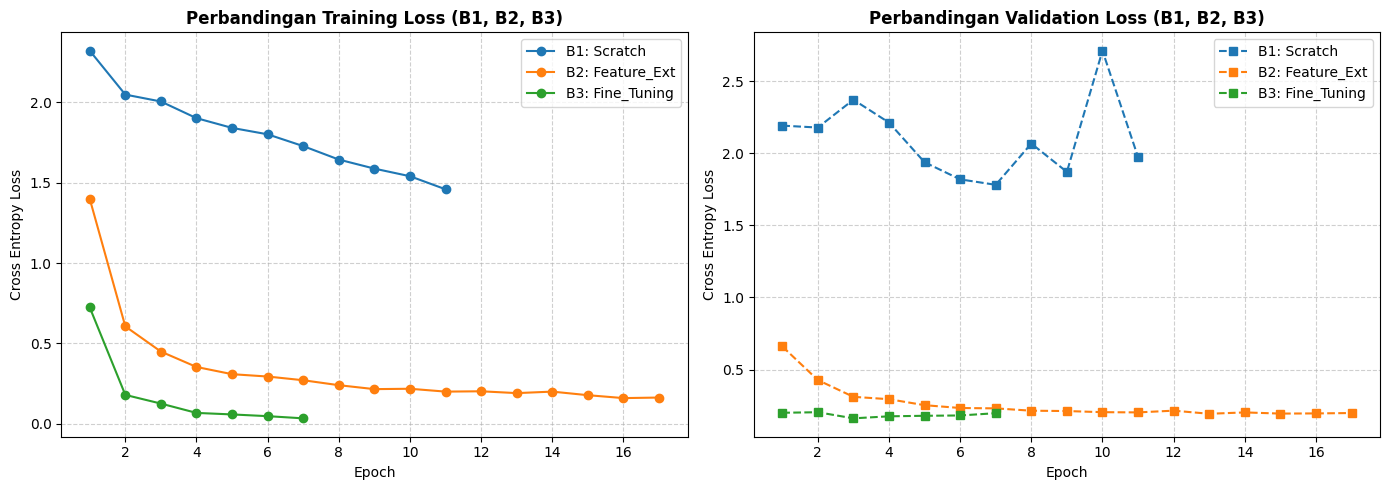

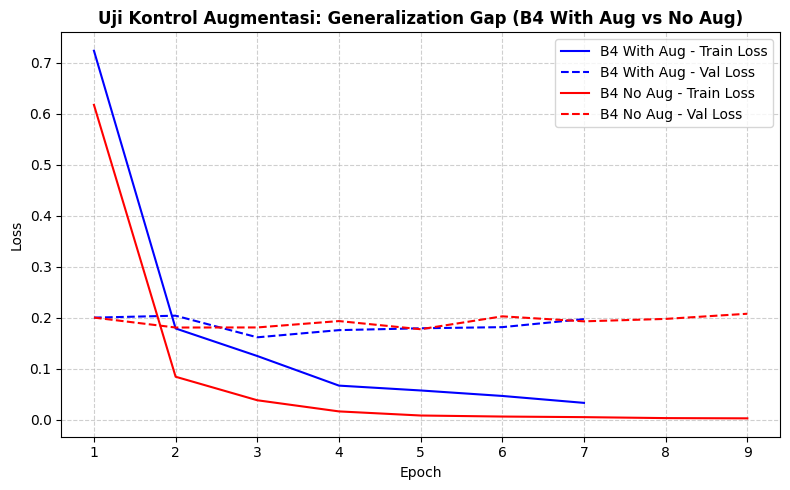

In [18]:
import matplotlib.pyplot as plt

# 1. GRAFIK KOMPARATIF B1, B2, B3 (Komponen C1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Training Loss
for cond in ["B1: Scratch", "B2: Feature_Ext", "B3: Fine_Tuning"]:
    if cond in all_histories:
        h = all_histories[cond]
        axes[0].plot(h['epoch'], h['train_loss'], marker='o', label=cond)

axes[0].set_title("Perbandingan Training Loss (B1, B2, B3)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross Entropy Loss")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Validation Loss
for cond in ["B1: Scratch", "B2: Feature_Ext", "B3: Fine_Tuning"]:
    if cond in all_histories:
        h = all_histories[cond]
        axes[1].plot(h['epoch'], h['val_loss'], marker='s', linestyle='--', label=cond)

axes[1].set_title("Perbandingan Validation Loss (B1, B2, B3)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross Entropy Loss")
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("./logs/loss_curves_B1_B2_B3.png", dpi=300)
plt.show()


# 2. GRAFIK UJI KONTROL AUGMENTASI: B4 With Aug vs B4 No Aug (Komponen C2 - Generalization Gap)
fig, ax = plt.subplots(figsize=(8, 5))

if "B4: With_Augment" in all_histories and "B4: No_Augment" in all_histories:
    h_aug = all_histories["B4: With_Augment"]
    h_noaug = all_histories["B4: No_Augment"]

    ax.plot(h_aug['epoch'],   h_aug['train_loss'],   'b-',  label='B4 With Aug - Train Loss')
    ax.plot(h_aug['epoch'],   h_aug['val_loss'],     'b--', label='B4 With Aug - Val Loss')
    ax.plot(h_noaug['epoch'], h_noaug['train_loss'], 'r-',  label='B4 No Aug - Train Loss')
    ax.plot(h_noaug['epoch'], h_noaug['val_loss'],   'r--', label='B4 No Aug - Val Loss')

ax.set_title("Uji Kontrol Augmentasi: Generalization Gap (B4 With Aug vs No Aug)", fontsize=12, fontweight='bold')
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()
ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("./logs/augmentation_gap_B4.png", dpi=300)
plt.show()

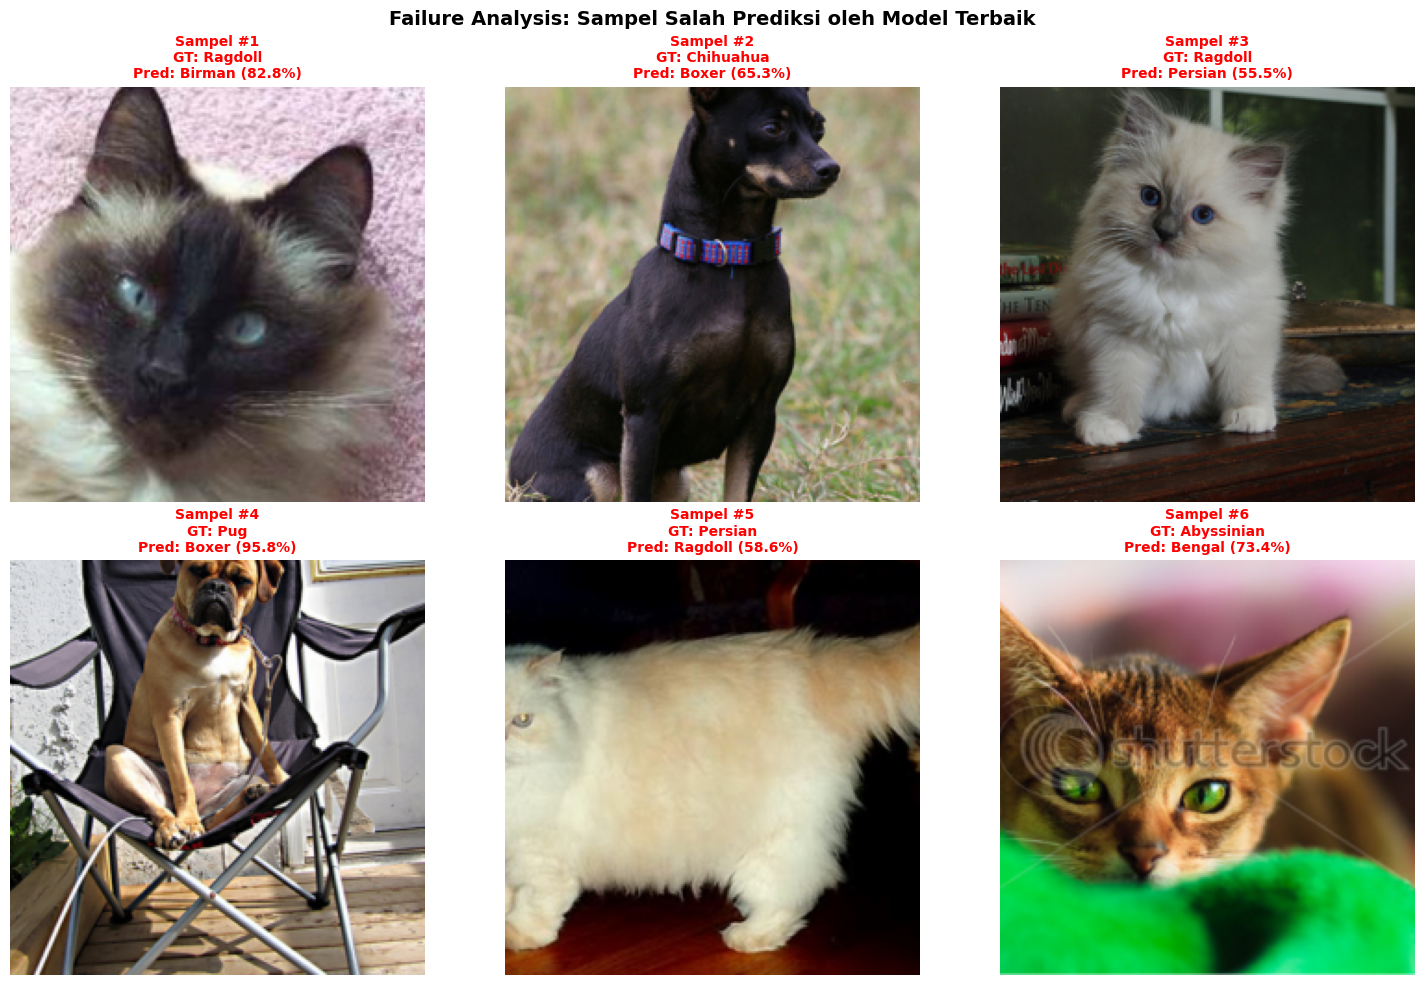


No   | Ground Truth (Aktual) | Prediksi Model       | Confidence  
1    | Ragdoll              | Birman               |  82.78%
2    | Chihuahua            | Boxer                |  65.32%
3    | Ragdoll              | Persian              |  55.52%
4    | Pug                  | Boxer                |  95.78%
5    | Persian              | Ragdoll              |  58.64%
6    | Abyssinian           | Bengal               |  73.43%


In [19]:
import torch.nn.functional as F

def extract_misclassified_samples(model, dataset, device, max_samples=8):
    """
    Mencari sampel test set yang salah diprediksi beserta confidence score-nya.
    """
    model.eval()
    misclassified = []

    # Iterasi langsung dari dataset uji agar mudah mengambil citra mentahnya
    for idx in range(len(dataset)):
        tensor_img, true_label = dataset[idx]
        input_tensor = tensor_img.unsqueeze(0).to(device)

        with torch.no_grad():
            output = model(input_tensor)
            probs = F.softmax(output, dim=1)
            conf, pred = torch.max(probs, dim=1)

        pred_label = pred.item()
        confidence = conf.item()

        if pred_label != true_label.item():
            misclassified.append({
                'tensor': tensor_img,
                'true_idx': true_label.item(),
                'pred_idx': pred_label,
                'true_name': new_label_to_name[true_label.item()],
                'pred_name': new_label_to_name[pred_label],
                'confidence': confidence
            })

            if len(misclassified) >= max_samples:
                break

    return misclassified

# Ambil 6-8 sampel dari test set menggunakan model terbaik
misclassified_samples = extract_misclassified_samples(best_model_overall, test_dataset, device, max_samples=6)

# Visualisasikan dalam Grid Plot
num_samples = len(misclassified_samples)
cols = 3
rows = (num_samples + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
axes = axes.flatten() if num_samples > 1 else [axes]

for i, sample in enumerate(misclassified_samples):
    ax = axes[i]
    img = unnormalize(sample['tensor']).permute(1, 2, 0).numpy()
    ax.imshow(img)

    title_text = (
        f"Sampel #{i+1}\n"
        f"GT: {sample['true_name']}\n"
        f"Pred: {sample['pred_name']} ({sample['confidence']*100:.1f}%)"
    )
    ax.set_title(title_text, fontsize=10, color='red', fontweight='bold')
    ax.axis('off')

# Matikan sumbu kosong jika jumlah sampel tidak genap
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.suptitle("Failure Analysis: Sampel Salah Prediksi oleh Model Terbaik", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("./logs/failure_analysis_grid.png", dpi=300)
plt.show()

# Cetak ringkasan dalam bentuk tabel teks untuk mempermudah penulisan laporan
print("\n" + "="*80)
print(f"{'No':<4} | {'Ground Truth (Aktual)':<20} | {'Prediksi Model':<20} | {'Confidence':<12}")
print("="*80)
for idx, s in enumerate(misclassified_samples):
    print(f"{idx+1:<4} | {s['true_name']:<20} | {s['pred_name']:<20} | {s['confidence']*100:6.2f}%")
print("="*80)

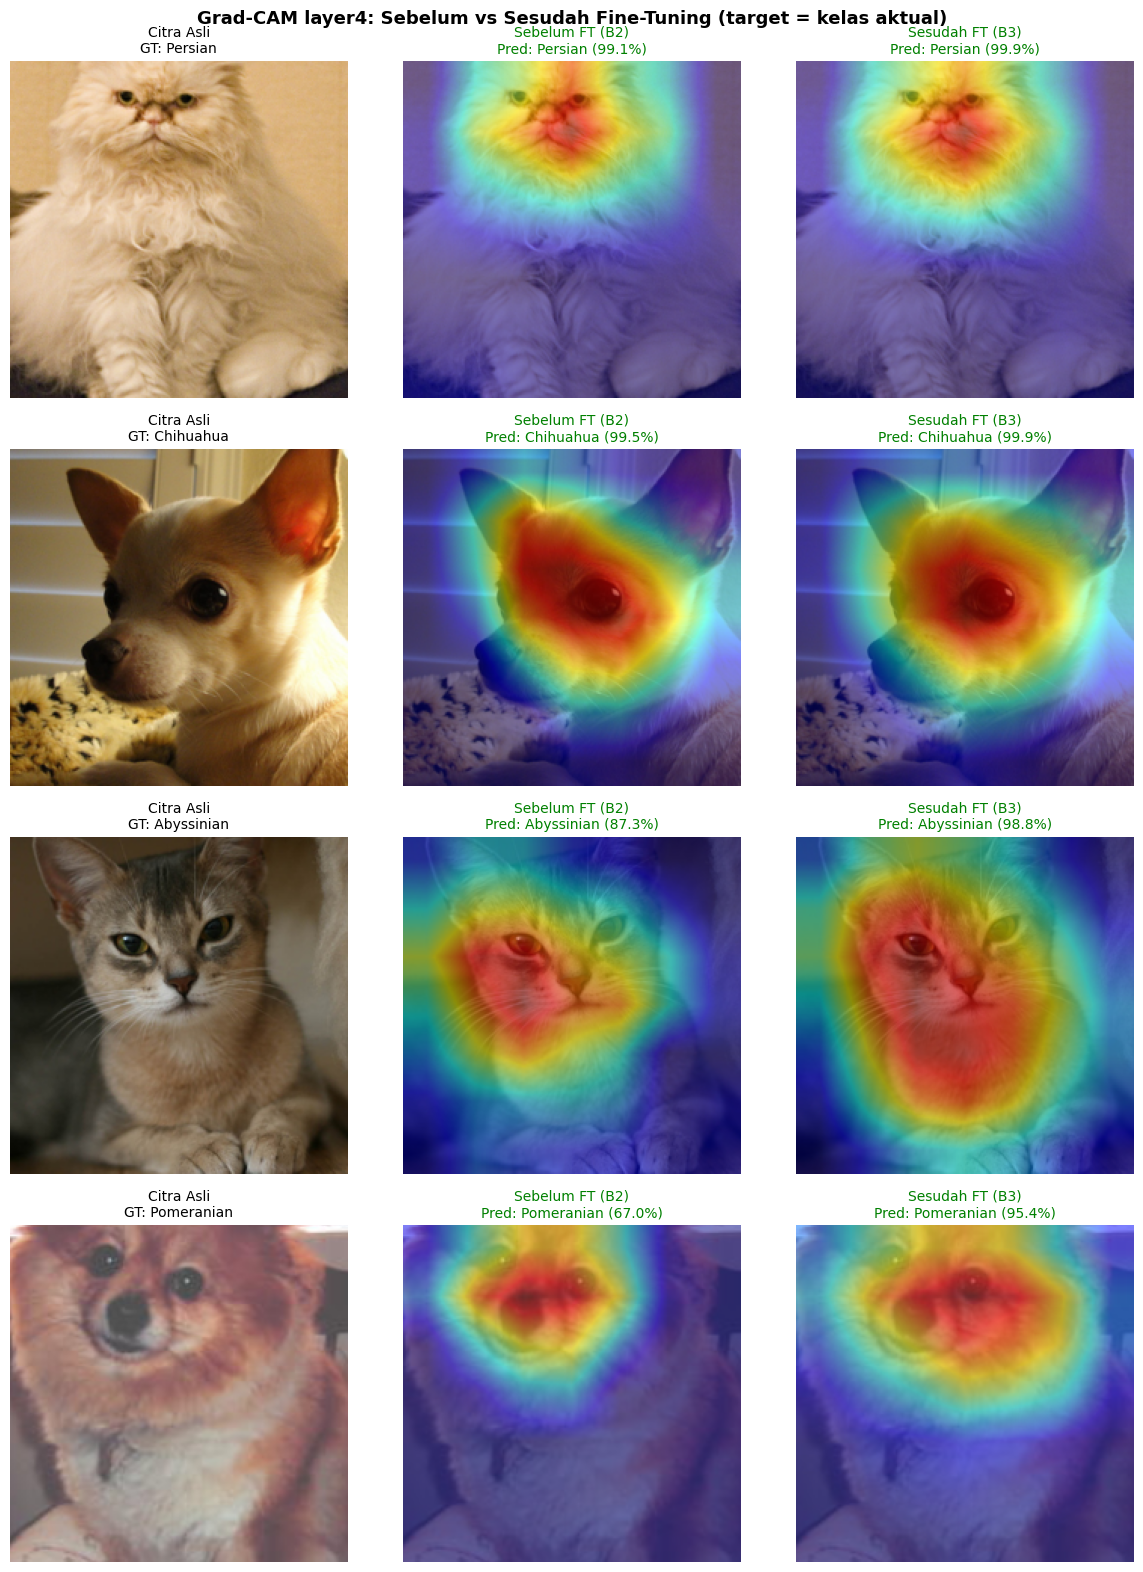

In [20]:
import cv2
import torch.nn.functional as F

def gradcam_heatmap(model, target_layer, input_tensor, target_class):
    """
    Grad-CAM pada target_layer. Hook dipasang & dilepas di dalam fungsi
    agar tidak menumpuk. Input diberi requires_grad=True supaya gradien
    tetap mengalir ke layer4 walaupun backbone dibekukan (kasus B2).
    """
    store = {}

    def fwd_hook(module, inp, out):
        store['act'] = out
        out.register_hook(lambda g: store.__setitem__('grad', g))

    handle = target_layer.register_forward_hook(fwd_hook)

    model.eval()
    model.zero_grad()
    x = input_tensor.clone().requires_grad_(True)

    output = model(x)
    probs = F.softmax(output, dim=1)
    conf, pred = probs.max(dim=1)
    output[0, target_class].backward()

    handle.remove()

    act = store['act'].detach()
    grad = store['grad'].detach()
    weights = grad.mean(dim=(2, 3), keepdim=True)            # GAP gradien per channel
    cam = F.relu((weights * act).sum(dim=1)).squeeze().cpu().numpy()
    cam = cv2.resize(cam, (224, 224))
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)  # Normalisasi [0, 1]
    return cam, pred.item(), conf.item()


# Model "sebelum" (B2: layer4 bobot ImageNet) vs "sesudah" (B3: layer4 di-fine-tune)
model_before = trained_models["B2"].to(device)
model_after  = trained_models["B3"].to(device)
compare_models = [("Sebelum FT (B2)", model_before), ("Sesudah FT (B3)", model_after)]

sample_indices = [0, 1, 2, 3]  # Ganti sesuai kebutuhan

fig, axes = plt.subplots(len(sample_indices), 3, figsize=(12, 4 * len(sample_indices)))

for row, idx in enumerate(sample_indices):
    tensor_img, true_lbl = test_dataset[idx]
    true_idx = true_lbl.item()
    input_tensor = tensor_img.unsqueeze(0).to(device)
    raw_img = unnormalize(tensor_img).permute(1, 2, 0).numpy()

    axes[row, 0].imshow(raw_img)
    axes[row, 0].set_title(f"Citra Asli\nGT: {new_label_to_name[true_idx]}", fontsize=10)
    axes[row, 0].axis('off')

    for col, (name, mdl) in enumerate(compare_models, start=1):
        cam, pred_idx, conf = gradcam_heatmap(mdl, mdl.layer4, input_tensor, true_idx)

        heat = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
        heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB) / 255.0
        overlay = 0.5 * raw_img + 0.5 * heat

        color = 'green' if pred_idx == true_idx else 'red'
        axes[row, col].imshow(overlay)
        axes[row, col].set_title(
            f"{name}\nPred: {new_label_to_name[pred_idx]} ({conf*100:.1f}%)",
            fontsize=10, color=color
        )
        axes[row, col].axis('off')

plt.suptitle("Grad-CAM layer4: Sebelum vs Sesudah Fine-Tuning (target = kelas aktual)",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("./logs/gradcam_before_after_FT.png", dpi=300)
plt.show()

In [21]:
# Jalankan di Colab untuk mengunduh log metrik & gambar
!zip -r logs_lengkap.zip ./logs
from google.colab import files
files.download('logs_lengkap.zip')

  adding: logs/ (stored 0%)
  adding: logs/gradcam_before_after_FT.png (deflated 8%)
  adding: logs/gradcam_layer4.png (deflated 7%)
  adding: logs/failure_analysis_grid.png (deflated 9%)
  adding: logs/augmentation_gap_B4.png (deflated 16%)
  adding: logs/augmentation_gap_B3_vs_B4.png (deflated 16%)
  adding: logs/epoch_histories.json (deflated 78%)
  adding: logs/metrics_summary.csv (deflated 53%)
  adding: logs/loss_curves_B1_B2_B3.png (deflated 17%)
  adding: logs/metrics_summary.json (deflated 82%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>